<a href="https://colab.research.google.com/github/haticecayli/dsa107-labs/blob/main/Lab07_Hatice_Beyza_%C3%87ayl%C4%B1_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA 107 — Lab 7: Review — a mini analysis from start to finish

**Week 8 · w/c 16 November 2026** · a review of DSA 101 lectures, weeks 1–5

**Name:** Hatice Beyza Çaylı   **Student ID:** 26022121461

---

### What you will produce

A runnable Colab notebook, pushed to your `dsa107-labs` repository. In it you answer **one question** from start to finish, on a table you have never seen:

> **Do noodles made in Japan get more stars than noodles made in South Korea?**

You look at the data, clean the columns you need, compare the two groups and write a claim, and draw labelled figures that support it. Then you look closer at the gap: how big it is next to the spread of the stars, and whether it stays the same for noodles that are sold in the same way.

### This lab is a review

Everything you need was in Labs 1–5. This notebook tells you **what** to produce in each part and **how it is graded**. It does **not** tell you how to do it: you plan the steps, choose the commands and write the code yourself. The **Command reference** below lists commands from the course.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas numpy matplotlib seaborn` in a new cell and try again.

### How to use this notebook

- Every part has one or more **Goals**. A Goal says what your work must produce. The **Graded** line under it shows exactly what earns the points.
- Write your code in the empty cell under the Goal. You may add more cells if you need them.
- There are **no Check lines** this time. Look at your own output and decide whether it makes sense.
- A code cell only shows the result of its **last line**. Put each thing you want to see inside `print()`.
- Lines marked *ready-made* are already written for you. Run them and do not change them.

### How you are graded

| Part | Where in this notebook | Points |
| --- | --- | --- |
| Meet the data | Goal 1 | 1 |
| Cleaning | Goal 2 | 1.5 |
| Comparing the two groups | Goals 3a, 3b (0.5 each) · Goal 4a (0.75) | 1.75 |
| Figures | Goals 3c, 4b (1 each) | 2 |
| The style check | Goal 4c | 0.75 |
| Interpretation | Q1, Q2, Q3, Q4 (0.75 each) | 3 |
| **Total** | | **10** |

**Rules for every part**

- **Any correct method** earns full points. There is not only one right way to write the code.
- Every figure needs an **x label**, a **y label** and a **title**.
- Every number in a written answer must be copied from **your own output**. If an earlier mistake gives you a wrong number, and you read that number correctly, you are not marked down a second time.
- Code that gives an error loses 0.25 for each cause of error.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__)
print("pandas", pd.__version__)

numpy 2.4.6
pandas 2.2.3


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series). `"col"` means the name of a column, in quotes.
Not every command here is needed for this lab — choosing the right one is part of the work.

**Loading and looking at a table**

| Command | What it does |
| --- | --- |
| `pd.read_csv(url)` | reads a CSV file into a DataFrame |
| `df.shape` | gives (number of rows, number of columns) |
| `len(df)` | gives the number of rows |
| `df.head(n)` | shows the first `n` rows (5 if you do not say) |
| `df.dtypes` | what each column is stored as: `object` = text, `int64` / `float64` = numbers |
| `df.info()` | prints the column names, their types and their non-missing counts |
| `s.describe()` | count, mean, std, min, quartiles (25%, 50% = the median, 75%) and max of a number column |

**Missing values and repeated rows**

| Command | What it does |
| --- | --- |
| `df.isna().sum()` | the number of missing values (`NaN`) in each column |
| `s.isna().sum()` | the same, for one column only |
| `df.duplicated().sum()` | how many rows are an **exact** copy of a row above them |
| `df.dropna(subset=["col"])` | removes the rows where `col` is missing — and only those rows |
| `df.dropna()` | removes every row that has **any** missing value, in any column |
| `s.fillna(s.mean())` | fills the missing values with the mean |
| `.copy()` | add it at the end, for example `df.dropna(subset=["col"]).copy()`: you get a new, separate table, so later changes do not give a warning |

**Looking at the labels of a text column**

| Command | What it does |
| --- | --- |
| `s.value_counts()` | every label and how many times it appears, most common first |
| `s.value_counts(dropna=False)` | the same, and it also counts the missing values |
| `s.nunique()` | how many different labels there are |
| `s.str.contains("abc", case=False, na=False)` | `True` for every value that has `abc` inside it, with big or small letters (`na=False`: a missing value counts as `False`) |
| `s.str.lower()` / `s.str.strip()` | makes all letters small / removes the spaces at the start and at the end |
| `s.replace({"old": "new", "old2": "new2"})` | changes every `"old"` into `"new"` (and every `"old2"` into `"new2"`) |
| `df["col"] = ...` | puts a column back into the table, replacing the old one |

**Choosing rows**

| Command | What it does |
| --- | --- |
| `df["col"] == "x"` | a **boolean mask**: for every row, is the value equal to `"x"`? |
| `df[mask]` | keeps only the rows where the mask is `True` |
| `df[(mask1) \| (mask2)]` | keeps the rows where **at least one** of the two masks is `True` |
| `df["col"].isin(["x", "y"])` | `True` for every row where the value is `"x"` or `"y"` |
| `mask.sum()` | how many rows are `True` |

**Group summaries**

| Command | What it does |
| --- | --- |
| `df.groupby("g")["x"].mean()` | the mean of `x` in each group of `g` |
| `.count()` `.median()` `.max()` `.min()` | put one of these in place of `.mean()` for another summary |
| `df.groupby("g")["x"].agg(["mean", "count"])` | the mean **and** the count of `x` in each group, in one table |
| `df.groupby(["g1", "g2"])["x"].agg(["mean", "count"])` | the same for every **pair** of groups, for example every country together with every style (Lab 3) |
| `table.unstack()` | moves the second group of a two-group table into columns (one row per first group) |
| `pd.crosstab(df["g1"], df["g2"])` | how many rows there are for every pair of groups |
| `table.sort_values("mean", ascending=False)` | sorts a table by its `mean` column, largest first |
| `table.round(2)` / `round(x, 2)` | rounds every value of a table / one number to 2 decimal places |
| `table.head(10)` | the first 10 rows of a table |

**Numbers**

| Command | What it does |
| --- | --- |
| `s.mean()` / `s.median()` / `s.std()` | mean / median / standard deviation of one column |
| `s.min()` / `s.max()` / `len(s)` | smallest value / largest value / number of values |
| `(s >= x).mean()` | what **share** of the values are `x` **or more** |
| `(s >= x).sum()` | **how many** values are `x` or more |

**Drawing and labelling**

The plot commands hand you back an *axes* object. Catch it in a variable (`ax = ...`) and you can label it.

| Command | What it does |
| --- | --- |
| `plt.figure(figsize=(8, 4))` | makes the **next** figure 8 wide and 4 tall |
| `ax = s.plot.bar(rot=0)` | a bar chart, one bar per row of `s`; `rot=0` keeps the names under the bars straight |
| `ax = s.plot.barh()` | the same, with horizontal bars |
| `ax = sns.boxplot(data=df, x="g", y="x")` | a box plot, one box per group (Lab 3) |
| `ax = s.plot.hist(bins=20)` | a histogram of `s` with 20 bars |
| `s2.plot.hist(bins=20, alpha=0.5, label="...", ax=ax)` | draws a second histogram on the **same** axes `ax`; `alpha=0.5` makes the bars see-through |
| `ax.legend()` | shows the `label` of every histogram or line in a small box |
| `ax.axvline(x, color="red")` | draws a vertical red line at `x` |
| `ax.set_ylim(0, 5)` | the y-axis goes from 0 to 5 |
| `ax.set_xlabel("...")` / `ax.set_ylabel("...")` | names the horizontal / the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `plt.show()` | shows the finished figure |

The bars of a bar chart must start at **0**: bars that start higher make a small difference look big.

## 1. Meet the data

This week's table is **Ramen Ratings**: **3,180 reviews of instant noodles** (ramen) from all over the world. All of them were written by **one reviewer**, on the website *The Ramen Rater*, up to 2019. Every noodle gets a score from **0 to 5 stars**. The table comes from the TidyTuesday project. You have **not** seen it before — that is on purpose.

| Column | What it means |
| --- | --- |
| `review_number` | the number of the review: 1 is the oldest review, 3180 the newest |
| `brand` | the company that makes the noodles, for example `Nissin` |
| `variety` | the name of the product, for example `Chicken Ramen` |
| `style` | how the noodles are sold: `Pack`, `Bowl`, `Cup`, `Tray`, `Box`, … |
| `country` | the country where the noodles were made |
| `stars` | the reviewer's score, from 0 (very bad) to 5 (excellent) |

> **Goal 1 · 1 pt.** Describe the whole table (the ready-made lines load it as `ramen`): its size, the type of every column, the first rows, the missing values in every column, the number of exact duplicate rows, and a summary of `stars`.
> **Graded:** size 0.2 · type of every column 0.2 · first rows 0.1 · missing values of every column 0.2 · number of exact duplicate rows 0.15 · summary of `stars` 0.15

In [15]:
# Goal 1 · 1 pt

# ready-made lines: do not change them
ramen_url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2019/2019-06-04/ramen_ratings.csv"
ramen = pd.read_csv(ramen_url)

print("Size:", ramen.shape)
print("Column types:", ramen.dtypes)
print("First rows:", ramen.head())
print("Missin values:", ramen.isna().sum())
print("Duplicate rows:", ramen.duplicated().sum())
print("Summary of stars:", ramen["stars"].describe())


Size: (3180, 6)
Column types: review_number    float64
brand             object
variety           object
style             object
country           object
stars            float64
dtype: object
First rows:    review_number            brand                       variety style   country  stars
0         3180.0          Yum Yum      Tem Tem Tom Yum Moo Deng   Cup  Thailand   3.75
1         3179.0       Nagatanien  tom Yum Kung Rice Vermicelli  Pack     Japan   2.00
2         3178.0          Acecook         Kelp Broth Shio Ramen   Cup     Japan   2.50
3         3177.0  Maison de Coree        Ramen Gout Coco Poulet   Cup    France   3.75
4         3176.0         Maruchan       Gotsumori Shio Yakisoba  Tray     Japan   5.00
Missin values: review_number     1
brand             0
variety           0
style             2
country           0
stars            14
dtype: int64
Duplicate rows: 0
Summary of stars: count    3166.000000
mean        3.688298
std         1.028214
min         0.000000
25% 

**Q1 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) *(0.35)* Fill in: The table has ___ rows and ___ columns. The columns stored as numbers are ___ ; the columns stored as text are ___ . `stars` has ___ missing values, and there are ___ exact duplicate rows.
(b) *(0.15)* What does **one row** of the table stand for?
(c) *(0.25)* Look at the summary of `stars`. Which one is bigger, the **mean** or the **median** (50%)? What does this tell you: does `stars` have a longer tail of **very low** scores or of **very high** scores?

(a) The table has **3180** rows and **6** columns. The columns stored as numbers are **review_number and starts** ; the columns stored as text are **brand, variety, style and country**. `stars` has **14** missing values, and there are **0** exact duplicate rows.


(b) One row of the table stands for one review of a specific instant product.


(c) The median (3.75) is bigger than the mean (3.68). This tells us that `stars` has a longer tail of very low scores.

## 2. Clean the columns you need

The question needs **two columns**: `country` (to make the two groups) and `stars` (to compare them). Clean these two columns before you compare anything. In Part 4 you will also use `style`; you do not need the other columns.

Remember the lecture's cleaning checklist: look at the table, find the missing values, check the labels, count the repeated rows — and **write down what you changed**.

> **Goal 2 · 1.5 pt.** Clean `stars` and `country`, and store the clean table as `clean`. Your output must show what you found and what you changed. At the end, print the number of rows of `clean`, and the number of noodles from Japan and from South Korea in it.
> **Graded:** rows with a missing `stars` value removed, and no other rows 0.4 · all the labels of `country` looked at, with the missing values 0.3 · every country that is written in more than one way given one label 0.45 · number of rows of `clean` printed 0.1 · number of noodles from Japan and from South Korea printed 0.25

In [16]:
# Goal 2 · 1.5 pt

clean = ramen.dropna(subset=["stars"]).copy()
print("Countries before cleaning:\n", clean["country"].value_counts(dropna=False).head(15))

clean["country"] = clean["country"].replace({"Korea": "South Korea", "USA": "United States", "UK": "United Kingdom"})
print("Number of rows in clean:", len(clean))

japan_count = (clean["country"] == "Japan").sum()
sk_count = (clean["country"] == "South Korea").sum()
print("Number of noodles from Japan:", japan_count)
print("Number of noodles from South Korea:", sk_count)



Countries before cleaning:
 country
Japan            529
United States    374
South Korea      355
Taiwan           330
China            207
Thailand         205
Malaysia         181
Hong Kong        155
Indonesia        150
Singapore        134
Vietnam          112
UK                69
Philippines       49
Canada            48
India             41
Name: count, dtype: int64
Number of rows in clean: 3166
Number of noodles from Japan: 529
Number of noodles from South Korea: 355


**Q2 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) *(0.35)* Fill in: The table had ___ rows; `clean` has ___ rows. In `country` I changed these labels: ___ . `clean` has ___ noodles from Japan and ___ noodles from South Korea.
(b) *(0.2)* Why must every country have **one** label before you use `groupby`? Explain it with an example from **your own** cleaning.
(c) *(0.2)* You removed the rows with a missing `stars` value. Why is that better here than filling them with the mean of `stars`? Give one reason.

(a) The table had **3180** rows; `clean` has **3166** rows. In `country` I changed these labels: **"Korea" to "South Korea", "USA" to "United States", and "UK" to "United Kingdom"** . `clean` has **529** noodles from Japan and **355** noodles from South Korea.


(b) Because `groupby` groups data by exact text matching. If a country has multiple labels (for example, "Korea" and "South Korea"), `groupby` treats them as two completely different countries and calculates two separate means. By standardising the label to a single name ("South Korea"), we ensure that all noodles from that country are gathered into one group and calculated accurately.


(c) Filling missing stars with the overall mean would artificially pull those specific noodles towards the global average, which distorts the actual group means we want to compare. Also, since there are only 14 missing values out of 3180, dropping them is a safe choice that doesn't cause a significant loss of data.

## 3. Compare the groups, and make a claim

Look at **every** country first, then at Japan and South Korea. Before you believe a group mean, ask: **how many noodles is it based on?**

> **Goal 3a · 0.5 pt.** For every country in `clean`, show the mean stars and the number of noodles, rounded to 2 decimals and sorted from the highest mean to the lowest. If the table is long, its first 10 rows are enough.
> **Graded:** mean of every country 0.15 · number of noodles of every country 0.15 · sorted, highest mean first 0.1 · rounded to 2 decimals 0.1

In [17]:
# Goal 3a · 0.5 pt

country_stats = clean.groupby("country")["stars"].agg(["mean", "count"]).round(2).sort_values("mean", ascending=False)
print(country_stats.head(10))


           mean  count
country               
Cambodia   4.20      5
France     4.19      4
Malaysia   4.16    181
Indonesia  4.11    150
Singapore  4.10    134
Brazil     4.04     12
Sarawak    4.00      5
Myanmar    3.95     14
Japan      3.91    529
Fiji       3.88      4


> **Goal 3b · 0.5 pt.** For Japan and for South Korea, print the number of noodles and the mean stars (2 decimals). Then print the **gap**: the mean of Japan minus the mean of South Korea.
> **Graded:** number of noodles of both countries 0.15 · mean stars of both countries 0.15 · the gap, Japan − South Korea 0.2

In [18]:
# Goal 3b · 0.5 pt

japan_mean = clean[clean["country"] == "Japan"]["stars"].mean()
japan_count = len(clean[clean["country"] == "Japan"])

sk_mean = clean[clean["country"] == "South Korea"]["stars"].mean()
sk_count = len(clean[clean["country"] == "South Korea"])

gap = japan_mean - sk_mean

print(f"Japan: {japan_count} noodles, mean stars: {japan_mean:.2f}")
print(f"South Korea: {sk_count} noodles, mean stars: {sk_mean:.2f}")
print(f"Gap between Japan and South Korea: {gap:.2f}")

Japan: 529 noodles, mean stars: 3.91
South Korea: 355 noodles, mean stars: 3.81
Gap between Japan and South Korea: 0.10


> **Goal 3c · Figure · 1 pt.** Draw one figure that compares the **mean** stars of Japan and South Korea and supports your claim.
> **Graded:** the figure compares the two countries 0.4 · x label 0.2 · y label 0.2 · title 0.2 · bars that do not start at 0: −0.2

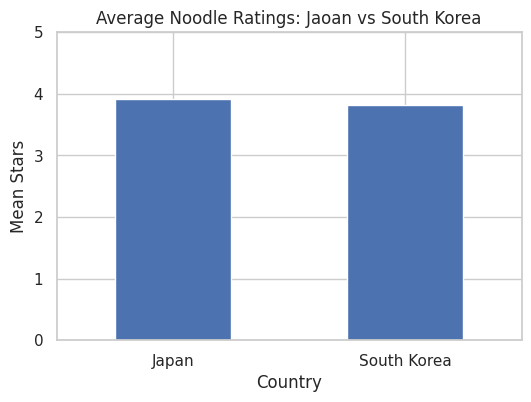

In [19]:
# Goal 3c · Figure · 1 pt

plot_data = pd.Series([japan_mean, sk_mean], index=["Japan", "South Korea"])

plt.figure(figsize=(6, 4))
ax = plot_data.plot.bar(rot=0)

ax.set_xlabel("Country")
ax.set_ylabel("Mean Stars")
ax.set_title("Average Noodle Ratings: Jaoan vs South Korea")

ax.set_ylim(0, 5)

plt.show()

**Q3 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) *(0.25)* Fill in: Japan has ___ noodles with a mean of ___ stars. South Korea has ___ noodles with a mean of ___ stars. The gap is ___ stars.
(b) *(0.15)* Write your **claim** in one sentence: which country's noodles get more stars, and by how much?
(c) *(0.15)* Read your figure in one sentence: what does it show about the two countries?
(d) *(0.2)* Fill in: In my Goal 3a table, the highest mean belongs to ___, and it is based on only ___ noodle(s). Why should you **not** trust this mean much?

(a) Japan has **529** noodles with a mean of **3.91** stars. South Korea has **355** noodles with a mean of **3.81** stars. The gap is **0.10** stars.


(b) Noodles made in Japan get more stars on average than those made in South Korea, with a gap of 0.10 stars.


(c) The bar chart visually confirms that the average star rating for Japan (3.91) is slightly higher than that for South Korea (3.81).


(d) In my Goal 3a table, the highest mean belongs to Cambodia, and it is based on only 5 noodle(s). You should not trust this mean much because an average calculated from a very small number of reviews is easily skewed by a single extreme opinion and is not statistically reliable.

## 4. Look closer at the gap

A difference between two means is only **one number**. Before you trust your claim, look at the gap from two more sides:

- **The spread.** How much do the stars vary inside each country? Is the gap big or small next to that?
- **A third variable.** Is the gap the same for noodles that are sold in the same way (the `style` column)? In Lab 3 you saw that a third variable can change the picture.

> **Goal 4a · 0.75 pt.** For Japan and for South Korea, print the **median** stars, the **SD** of the stars, and the **share** of noodles with **4 stars or more** (2 decimals).
> **Graded:** median of both countries 0.25 · SD of both countries 0.25 · share with 4 stars or more of both countries 0.25

In [20]:
# Goal 4a · 0.75 pt

japan_stars = clean[clean["country"] == "Japan"]["stars"]
sk_stars = clean[clean["country"] == "South Korea"]["stars"]

japan_median = japan_stars.median()
japan_sd = japan_stars.std()
japan_share_4plus = (japan_stars >= 4).mean()

sk_median = sk_stars.median()
sk_sd = sk_stars.std()
sk_share_4plus = (sk_stars >= 4).mean()

print(f"Japan: median {japan_median:.2f}, SD {japan_sd:.2f}, share with 4 stars or more {japan_share_4plus:.2f}")
print(f"South Korea: median {sk_median:.2f}, SD {sk_sd:.2f}, share with 4 stars or more {sk_share_4plus:.2f}")

Japan: median 4.00, SD 0.99, share with 4 stars or more 0.56
South Korea: median 3.75, SD 0.85, share with 4 stars or more 0.47


> **Goal 4b · Figure · 1 pt.** Draw a **second** figure that shows the **whole distribution** of stars in each of the two countries — every noodle, not only one number per country.
> **Graded:** the figure shows the distribution of stars of both countries 0.4 · x label 0.2 · y label 0.2 · title 0.2

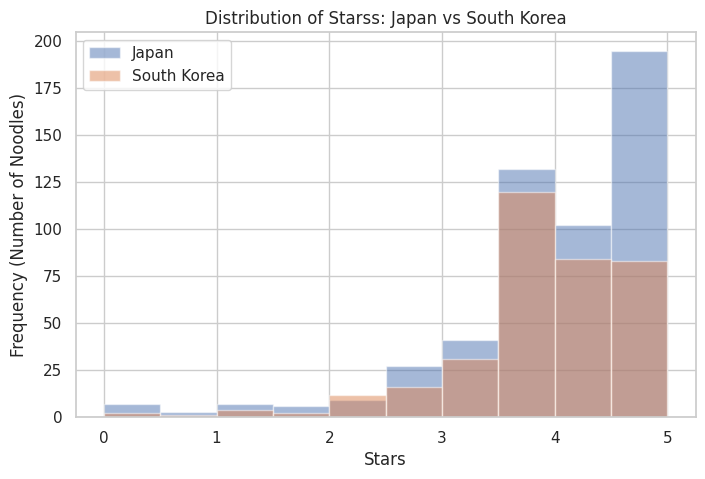

In [21]:
# Goal 4b · Figure · 1 pt

plt.figure(figsize=(8,5))

ax = japan_stars.plot.hist(bins=10, alpha=0.5, label="Japan")
sk_stars.plot.hist(bins=10, alpha=0.5, label="South Korea", ax=ax)

ax.set_xlabel("Stars")
ax.set_ylabel("Frequency (Number of Noodles)")
ax.set_title("Distribution of Starss: Japan vs South Korea")
ax.legend()

plt.show()

> **Goal 4c · 0.75 pt.** Check the gap inside each **style**: for every style, show the mean stars and the number of noodles of Japan and of South Korea, in one table (2 decimals).
> **Graded:** mean stars for every pair of country and style 0.3 · number of noodles for every pair of country and style 0.3 · the table holds only Japan and South Korea 0.15

In [22]:
# Goal 4c · 0.75 pt

jp_sk = clean[clean["country"].isin(["Japan", "South Korea"])]
style_check = jp_sk.groupby(["style", "country"])["stars"].agg(["mean", "count"]).unstack().round(2)

print("Mean stars and count by style and country:")
print(style_check)

Mean stars and count by style and country:
         mean              count            
country Japan South Korea  Japan South Korea
style                                       
Bowl     4.01        3.83  185.0        83.0
Box      4.88         NaN    8.0         NaN
Cup      3.74        3.52  100.0        45.0
Pack     3.84        3.90  195.0       209.0
Tray     4.09        3.48   41.0        18.0


**Q4 · 0.75 pt.** Copy the numbers from **your own output above**.
(a) *(0.25)* Fill in: Japan: median ___ , SD ___ , share with 4 stars or more ___ . South Korea: median ___ , SD ___ , share with 4 stars or more ___ .
(b) *(0.15)* Compare the gap between the two means (Q3) with the SD inside each country. Is the gap big or small next to the spread? Use your Goal 4b figure in your answer.
(c) *(0.2)* Look at your Goal 4c table. Does Japan get more stars than South Korea in **every** style? What does this tell you about your claim from Q3?
(d) *(0.15)* All the stars in this table come from **one** reviewer. Why can you **not** say that one country's noodles are better **for everybody**?

(a) Japan: median **4.00** , SD **0.99** , share with 4 stars or more **0.56**. South Korea: median **3.75** , SD **0.85**, share with 4 stars or more **0.47**.

(b) The gap between the two means (0.10) is very small next to the spread of the stars inside each country (SD of 0.99 and 0.85). The Goal 4b figure shows that the two distributions overlap almost completely, meaning the 0.10 gap is a tiny shift rather than a clear separation between the two countries.

(c) No, Japan does not get more stars in every style. In the "Pack" style, South Korea's mean (3.90) is actually higher than Japan's (3.84). This tells me that my general claim from Q3 (that Japan gets more stars) is too simple; the result changes depending on how the noodles are packaged.


(d) Because all the ratings reflect only one person's specific taste and preferences. What this reviewer considers a 5-star noodle might be too salty for someone else, so we cannot claim one country is objectively better for everybody based on subjective data from a single source.

## 5. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** https://github.com/haticecayli/dsa107-labs

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] Both figures (Goals 3c and 4b) have an x label, a y label and a title — and they are two different figures
- [ ] All four written answers (Q1–Q4) are filled in — a figure or a table with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab07_Firstname_Lastname.ipynb` — open it once more before you upload it, to be sure it is the **filled** notebook and not the empty starter
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.

Appendix: AI Usage Log
AI Assistant Used: Google Gemini
Date(s) of Use: 18 November 2026
Task / Context: DSA 107 - Lab 7 (Review: a mini analysis from start to finish)

1. Purpose of AI Assistance:
I used the AI assistant as a collaborative tutor to help break down the lab requirements, construct accurate Python code (using pandas and matplotlib) based strictly on the course's command reference, and to help structure my written interpretations in English for questions Q1 through Q4.

2. Summary of Prompts & Interactions:

Goal 1 & 2 (Data Understanding & Cleaning): I asked the AI to help me write the commands to inspect the dataset's shape, data types, and missing values. After identifying inconsistencies in the country column, I asked for the correct syntax to standardise the names (e.g., converting "Korea" to "South Korea") and remove missing values in the stars column.

Goal 3 & 4 (Grouping & Plotting): I requested assistance in chaining pandas methods (.groupby, .agg, .unstack) to calculate counts, means, medians, and standard deviations. I also asked for the standard matplotlib code to generate a bar chart and an overlapping histogram, ensuring the axes started at 0 and were properly labelled.

Interpretation (Q1-Q4): I ran all the generated code in my own Google Colab environment and pasted the exact numerical outputs back to the AI. I then asked the AI to help me formulate clear, analytical sentences in English based on my own runtime outputs to answer the interpretation questions.

3. Modifications & Own Work:
The AI acted as a guide; all code execution was performed by me in Colab to verify the results. I reviewed the AI's suggested text for the interpretation questions, ensured they correctly matched the numerical outputs I generated, and integrated them into the final notebook.